# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Wu 2021's malignant manifold is a **round, near-isotropic disk** organised by cell cycle and
recurrent breast metaprograms, not an elongated developmental strip. We fit a **principal
curve** (ElPiGraph, non-branching) on the *joint* embedding — never a re-embedding — root it
at the gastrulation/somitogenesis-high tip, and read the signature gradients along
pseudotime. The topology call (curve, not tree) is made from the embedding: a PPT tree
collapses to a central point and the curve captures under half the 2D spread — there is no
dominant 1D axis and no fork. The scoping is the whole manifold: the two lobes carry
near-identical developmental means, so the proliferation split is orthogonal to (not a
confound hiding) any developmental axis. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
CITE = 'Wu et al., 2021'

### Load processed manifold and score developmental modules
Keep all cells on their *original joint embedding coordinates* — no re-embedding. The three
embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored against the
shared **union** control pool and graph-smoothed to read geography rather than 10x per-cell
dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 24489 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.66
Gast: 78/81 genes present
pSom: 95/98 genes present
Crest: 103/104 genes present


### Scope decision — whole manifold vs a single lobe (data-driven)
Test whether the developmental axis is confined to the low-cycling lobe (Kürten case, where
scoping is justified) or spans both (Bischoff/Sun case, keep whole manifold). Here the two
compartments have **near-identical** smoothed developmental means, so neither lobe carries a
distinct developmental axis — excluding either would not isolate a cleaner gradient. The
whole manifold is the honest object.

In [4]:
print('per-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
print()
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('-> lobes carry the same developmental means; keep whole manifold (no scoping).')
sub = adata

per-compartment smoothed developmental means:
                   Gast_sm  pSom_sm  Crest_sm
compartment                                  
Low-cycling        -0.0223   0.0286   -0.0352
Cycling/Metabolic  -0.0278   0.0263   -0.0285

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.47
  Crest_sm vs Gast_sm: r = +0.03
  Crest_sm vs pSom_sm: r = -0.71
-> lobes carry the same developmental means; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph) and read the topology
`Nodes/epg_lambda/epg_mu` give a fold-free monotone backbone. The **fold self-approach
ratio** (min distance between graph-non-adjacent nodes, in median-edge units) > 1 certifies
the curve does not fold back. We also report how much of the embedding variance the curve
captures — low here (round blob, weak 1D structure) and **0 forks** (no bifurcation).

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1); F = sub.uns['graph']['F'].T
proj = F[hard]; resid = np.sqrt(((sub.obsm['X_umap']-proj)**2).sum(1))
tot = np.sqrt(((sub.obsm['X_umap']-sub.obsm['X_umap'].mean(0))**2).sum(1))
print(f'curve captures {1-(resid.var()/tot.var()):.2f} of embedding variance (low => round blob, weak 1D axis)')
assert forks == 0, 'expected a non-branching curve'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)
curve captures 0.48 of embedding variance (low => round blob, weak 1D axis)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental
origin. Pseudotime then flows toward the neural-crest end. We report the gradient of each
smoothed signature and of the cell-cycle score along pseudotime (the latter should be
orthogonal — pseudotime is not a proliferation axis).

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0208 pSom=+0.0274 Crest=-0.0362
tip 2: Gast=-0.0251 pSom=+0.0212 Crest=-0.0242
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.372 p=0.0e+00
  pSom_sm: rho=-0.224 p=6.2e-275
  Crest_sm: rho=+0.555 p=0.0e+00
  cyc_score: rho=+0.004 p=5.0e-01


### Reorient to house style (pseudotime left -> right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation). This manifold is
already **horizontal** in the raw embedding, so the house transform is the **identity**
(X_umap_lin = raw_umap). The assertion confirms low pseudotime lands on the left.

In [7]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])        # identity: already horizontal
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: identity (already horizontal); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: identity (already horizontal); corr(x_lin, pseudotime) = +0.99


### Save manifold + trajectory figure (deliverable)
Sanitise the non-serialisable ElPiGraph `uns['epg']` entry (keep node positions; the graph
lives in `uns['graph']`), then render pseudotime in house style (cividis, `(3.5,1.5)`).

saved manifold.h5ad + manifold.pdf


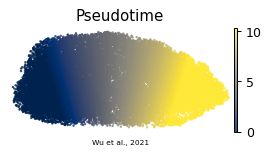

In [8]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=15, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12, CITE, ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')